### Import Required Modules

In [1]:
from pathlib import Path
import sys

import numpy as np
import allantools
from allantools import noise
from math import pi
import matplotlib.pyplot as plt
import pandas as pd

from scipy.io.wavfile import write
import scipy.stats as stats


import clock_confidence_intervals
from clock_confidence_intervals import required_runtime
from clock_confidence_intervals import error_bars
from clock_confidence_intervals import error_bars_tch
from clock_confidence_intervals import error_bars_list
from clock_confidence_intervals import error_bars_tch_list
from clock_confidence_intervals import gamma_factor
from clock_confidence_intervals import edf_formula
from clock_confidence_intervals import string_noise_type
from clock_confidence_intervals import plot_error_bars

# Error Bars Notes

### Confidence Interval Calculation Process and primary functions

Confidence intervals can be calculated for any of the 2-sample or 3-sample variances, including:

1. Overlapping ADEV
2. Non-overlapping ADEV
3. MDEV
4. TDEV
5. HDEV

error_bars takes in 2-port phase data and a single deviation data and calculates a confidence interval for the given tau. It also takes in the sampling rate, confidence level, two-sample vs 3-sample variance, minimum desired degrees of freedom (default 10), minimum decimated array length to use for noise identification (default 5), whether to print warnings, whether to use a fallback degrees of freedom value for low-confidence noise identification, whether to use overlapping noise identification, and for OADEV only whether to use Greenhall or the simple formula degrees of freedom formula.  See the function documentation for more details on each of these parameters. 

If there is enough data to perform noise identification, error_bars calculates the noise type using the lag 1 ACF Noise Identification algorithm (Riley and Greenhall, 2004), calculates the corresponding chi-squared degrees of freedom using Greenhall's algorithm (Greenhall and Riley, 2004), and calculates a confidence interval using the chi-squared distribution. 

error_bars_tch takes the phase data as a list of three phase difference arrays $[d_{12}, d_{23}, d_{31}]$, the deviation value of each of the clock phase differences as a list of three clock deviation values, $[\sigma_1, \sigma_2, \sigma_3]$ at $\tau$,, and the clock number (1,2, or 3)to calculate error bars for. It follows the same logic as error_bars, but also calculates a three-cornered hat Gamma factor for each clock (Ekstrom and Koppang, 2006), which is applied to the reference clock degrees of freedom to get the TCH degrees of freedom. This factor has not yet been tested on deviations besides the ADEV and OADEV but should apply to other deviation types also. There is an additional optional parameter to adjust for bias in the TCH deviation estimate for the ADEV or OADEV (Ekstrom and Koppang, 2006).

error_bars_list and error_bars_tch_list use error_bars and error_bars_tch respectively to calculate error bars over a list of averaging intervals. Instead of taking in a single deviation data value for each clock, they take in a list of tau values (or a string corresponding to a selection of tau values), and the AllanTools deviation function to calculate error bars for. 

print_error_bars_table takes a list of error bars and prints a table of the results. It also takes in a clock name, deviation name, and output file name.

plot_error_bars takes a list of error bars and plots the deviation with error bars vs tau on a log-log plot. It also takes in a clock name, deviation name, and output file name.

required_runtime takes a sample rate, averaging interval, target minimum degrees of freedom, and 2-port vs TCH flag with the target clock and relative sigmas if relevant, and calculates the runtime needed to reach a target DOF at a given tau. It also takes in optional minimum decimated array length to use as a marker for runtime calculations, and the power-law exponent of the noise typs to consider. It defaults to all noise types if no exponents are provided.

Addtional notes:

The noise identification for the TCH assumes that all clocks exhibit the same dominant noise type. To identify the noise type, the lag 1 ACF Noise ID algorithm is applied to both clock differences with that clock and if they do not agree,the noise type corresponding to fewer degrees of freedom is chosen. 

If noise_id_overlapping is used, the noise identification is applied to the decimated phase data in an overlapping manner to use all of the available data. This method provides only minimally better noise identification results and is much slower than the non-overlapping method used by the standard Lag 1 ACF Noise ID algorithm.

The df_falback parameter will be used to fallback, or default, to a noise type with a lower degrees of freedom when the identified noise is phase modulation but the averaging interval is larger than where we could expect to see phase modulation. Monte Carlo simulations show that white frequency modulation is frequently identified as phase modulation.

The calculated degrees of freedom are generally not trustworthy for TCH measurements when the calculated degrees of freedom are below 10 (see Ekstrom and Koppang, 2006; this also agrees with the results of Monte Carlo simulatios that I ran independently).

Allowed noise types for error bars:

_NOISE_TYPE_NAMES = {

    2: "White PM",
    1: "Flicker PM",
    0: "White FM",
    -1: "Flicker FM",
    -2: "Random Walk FM",

}



### Additional Error Bars Calculations Notes


Additional Notes on Implementation/Deviations from Algorithms or Papers

Empirically, from MC simulations a relatively low deviation clock has accurate
95% coverage until calculated df goes below 10 (see Ekstrom & Koppang Degrees of
Freedom and Three-Cornered Hats (2006); also agrees with MC simulations I ran.).
This coverage breaks below 10 d.f. especially when clocks are dominated by
different noise types.

How does "fallback" noise type work?:
I ran MC simulations on pure and weighted 2-noise type data with 1 dominant, for 
sample sizes of N=512 (4,000 trials) and N=2^18 (200 trials, technically too small
to be valid MC). I used these to determine roughly at what point an identified
noise type was likely to actually be a noise type with lower degrees of freedom.

Why is minimum length of decimated arrays (approximately N/M) required to be at 
least 5 by default?:
At the data lengths we expect to be calculating ADEV for (N = 10^2 to 10^7),
only WPM and FPM show degrees of freedom above 10 when N/M>8. The remaining noise
types are at or below 10 d.f. for N/M <= 8, even for 2-port calculations.

We manually exclude values here instead of passing to degres of freedom calculations
since we do not expect clocks to display dominant WPM or FPM at such large averaging 
intervals but with N/M small other noise types can be mis-identified as WPM or FPM,
leading to artifically large degrees of freedom and overconfident error bars.

Misc. Note: FFM noise type still produced relatively innacurate (compared to other
noise types) degrees of freedom and confidence intervals even when degrees of freedom
are still well above 10. However, this is a known problem with Flicker noise and 
less effort was taken to adjust for this since  coverage is still good for small
averaging intervals (below M=20), and WPM and FPM are only expected to be dominant
at extremely small averaging intervals (around 1s).

This notebook and confidence_intervals does not currently pre-remove frequency drift when calculating any deviations.

This analysis on the degrees of freedom depends on no frequency drift in the time
series, and that the three individual clocks have the same number of d.f. (i.e,
the dominant noise type is the same for each clock).

From Howe, Allan, & Barnes in Properties of Signal Sources and Measurement Methods (1981),
on the simple degrees of freedom formula for OADEV calculations:
All [ideal reference d.f.] values are thought to be accurate to within one 
percent or better for the cases of white PM, white FM, and random walk FM. A 
larger tolerance should be allowed for the flicker cases.


#   Degrees of Freedom Pre-Measurement Calcuations

### Notes:
Allowed noise types for error bars:

_NOISE_TYPE_NAMES = {

    2: "White PM",
    1: "Flicker PM",
    0: "White FM",
    -1: "Flicker FM",
    -2: "Random Walk FM",

}
Below, input the expected dominant noise type at the desired tau value.
Typically, clocks will be dominated by WPM/FPM only at very small averaging intervals,
WFM in the short term (1-100s), FFM in the medium-term (100-10,000s) and RWFM in
the longer averaging intervals.
Note that the important thing is the relative deviation values, so equivalently,
you can set one clock's deviation to 1 and input the others relative to it.
The TCH degrees of freedom calculation follows:
$$\text{remaining d.f.} = \Gamma \cdot (\text{ideal reference d.f.})$$

$$\Gamma = \frac{2\sigma_i^4}{2\sigma_i^4 + \sigma_1^2\sigma_2^2 + \sigma_1^2\sigma_3^2 + \sigma_2^2\sigma_3^2}$$

where ideal reference d.f. is a function of noise type, $N$ = number of sample values, $m = \tau / \tau_0$.

Lastly, input desired degrees of freedom. 

Note: "achieved DOF" is what df_perfect_ref(n_required, m, alpha) * gamma
actually comes out to at n_required. It equals the target when
binding = "dof", but can be well above target when binding =
"noise_id_wall" or "domain" -- those floors sometimes return more
degrees of freedom than requested as a side effect of the other
constraint being the larger one.


## Calculate Required Sample Time for Desired Degrees of Freedom

In [2]:
# Allowed noise types:
# _NOISE_TYPE_NAMES = {
#     2: "White PM",
#     1: "Flicker PM",
#     0: "White FM",
#     -1: "Flicker FM",
#     -2: "Random Walk FM",
# }

#   Measurement parameters

#   Measurement rate (Hz)
rate = 1

#   Averaging interval tau (s) at which to calculate runtime
tau = 1

#   Expected dominant noise type power law exponent alpha at the desired tau value; 
# input integer, list of integers, or 'all' to solve for all 5  noise types
dominant_noise_type = 'all'

#   Expected relative clock deviations for the TCH gamma factor (see note
#   above -- only the ratios matter, so set one clock to 1 and the others
#   relative to it). Real measured/expected sigma values work just as well
#   as normalized ones. Symmetric (all equal) by default.
relative_sigmas = (.1, 1.0, 1.0)

#   Required Degrees of Freedom
df = 1

#   Which clock's degrees of freedom to solve for (1, 2, or 3)
target_clock = 1

#   dominant_noise_type = 'all'' means "solve for all 5 known noise types"
alphas = dominant_noise_type if dominant_noise_type is not None else 'all'

planning = required_runtime(target_df=df, tau=tau, rate=rate, alphas=alphas,
                             reference_clock=False, target_clock=target_clock,
                             relative_sigmas=relative_sigmas)

print(f"Target: {df} degrees of freedom at tau = {tau} s, rate = {rate} Hz\n")
for r in planning['per_alpha']:
    print(f"{r['noise_type']:<16} N = {r['n_required']:>10,}   "
          f"runtime = {r['runtime_hours']:>10.2f} h   "
          f"({r['tau_multiples']:.0f}x tau)   "
          f"achieved DOF = {r['degrees_of_freedom']:>8.2f}   "
          f"binding: {r['binding_constraint']}")

if len(planning['per_alpha']) > 1:
    w = planning['worst_case']
    print(f"\nWorst case (plan around this if the dominant noise type is unknown): "
          f"{w['noise_type']}, {w['runtime_hours']:.2f} hours")

#   Note: "achieved DOF" is what edf_formula(n_required, m, alpha) * gamma
#   actually comes out to at n_required. It equals the target when
#   binding = "dof", but can be well above target when binding =
#   "noise_id_wall" or "domain" -- those floors sometimes hand you more
#   degrees of freedom than you asked for as a side effect of the other
#   constraint being the larger one.




Target: 1 degrees of freedom at tau = 1 s, rate = 1 Hz

White PM         N =     10,203   runtime =       2.83 h   (10203x tau)   achieved DOF =     1.00   binding: dof
Flicker PM       N =      8,351   runtime =       2.32 h   (8351x tau)   achieved DOF =     1.00   binding: dof
White FM         N =      7,654   runtime =       2.13 h   (7654x tau)   achieved DOF =     1.00   binding: dof
Flicker FM       N =      5,869   runtime =       1.63 h   (5869x tau)   achieved DOF =     1.00   binding: dof
Random Walk FM   N =      5,102   runtime =       1.42 h   (5102x tau)   achieved DOF =     1.00   binding: dof

Worst case (plan around this if the dominant noise type is unknown): White PM, 2.83 hours


#   Print Chart of Estimated Chi-Square Degrees of Freedom

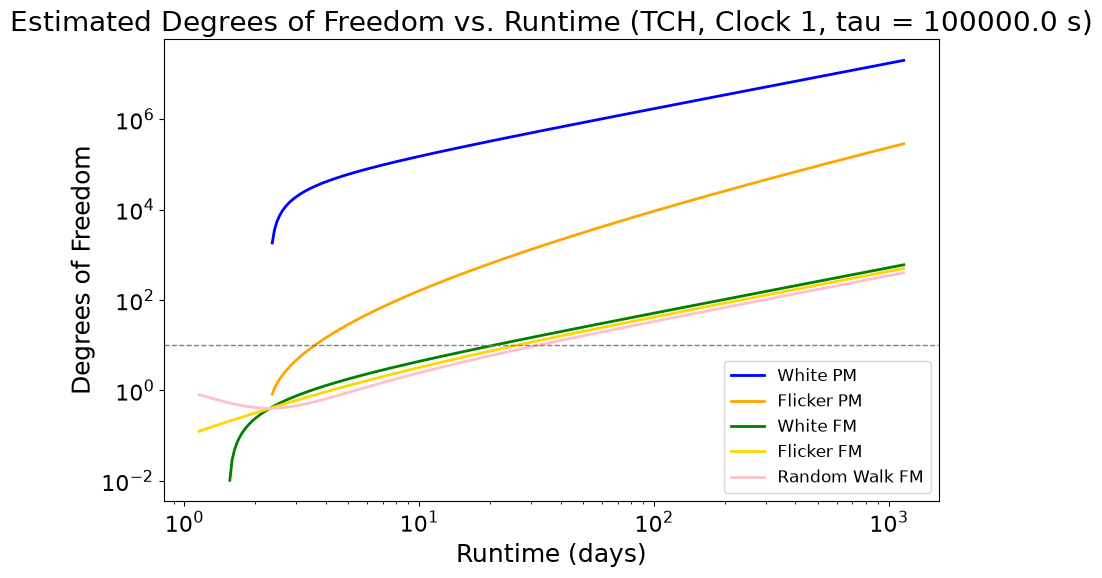

In [3]:
#   Chart of estimated degrees of freedom vs. runtime, one curve per noise type

#   Allowed noise types:
# _NOISE_TYPE_NAMES = {
#     2: "White PM",
#     1: "Flicker PM",
#     0: "White FM",
#     -1: "Flicker FM",
#     -2: "Random Walk FM",
# }

#   Measurement type: True for 2-port (perfect reference clock), False for TCH
reference_clock = False

#   Measurement rate (Hz)
rate = 1

#   Averaging interval tau (s) at which to evaluate degrees of freedom
tau = 1e5

#   Noise type power-law exponent alpha to plot; input a single integer
#   (2, 1, 0, -1, or -2), or None to plot all 5 known noise types
noise_type = None

#   TCH-only: expected relative clock deviations for the gamma factor (see
#   note above -- only the ratios matter Ignored if reference_clock = True.
relative_sigmas = (1.0, 1.0, 1.0)

#   TCH-only: which clock (1, 2, or 3) to plot degrees of freedom for.
#   Ignored if reference_clock = True.
target_clock = 1

#   Fixed noise-type -> color mapping so a line's color always means the
#   same noise type across plots, regardless of which types are selected
_ALPHA_COLORS = {2: 'blue', 1: 'orange', 0: 'green', -1: 'gold', -2: 'pink'}

alpha_list = [2, 1, 0, -1, -2] if noise_type is None else [noise_type]
gamma = 1.0 if reference_clock else gamma_factor(target_clock, *relative_sigmas)

#   Sample sizes N to sweep over, log-spaced from just above the decimation
#   factor m = tau * rate (df_perfect_ref's domain requires N > m) up to a
#   generous multiple of it
m = tau * rate
n_values = np.unique(np.geomspace(m + 1, max(10**7, m * 1000), 300).astype(int))

fig, ax = plt.subplots(figsize=(10, 6))

for alpha in alpha_list:
    runtime_days = []
    dof_values = []
    for n in n_values:
        try:
            dof = edf_formula(n, m, alpha) * gamma
        except (ValueError, ZeroDivisionError):
            continue
        if not np.isfinite(dof) or dof <= 0:
            continue
        runtime_days.append(n / rate / (3600*24))
        dof_values.append(dof)
    ax.loglog(runtime_days, dof_values, color=_ALPHA_COLORS[alpha],
               linewidth=2, label=string_noise_type(alpha))

ax.axhline(10, color='gray', linestyle='--', linewidth=1)

mode_label = '2-Port' if reference_clock else f'TCH, Clock {target_clock}'
ax.set_xlabel('Runtime (days)', fontsize=18)
ax.set_ylabel('Degrees of Freedom', fontsize=18)
ax.set_title(f'Estimated Degrees of Freedom vs. Runtime ({mode_label}, tau = {tau} s)', fontsize=20)
ax.tick_params(axis='both', labelsize=16)
ax.legend(fontsize=12)
plt.show()

## Calculate OADEV error bars for simulated data

### Generate synthetic phase data

In [4]:
def generate_phase(b_values, qd_values, points, seed_sequence):
    np.random.seed(seed_sequence.generate_state(1, dtype=np.uint32)[0])
    total_phase = np.zeros(points)
    for qd, b in zip(qd_values, b_values):
        noise = allantools.Noise(nr=points, qd=qd, b=b)
        noise.generateNoise()
        total_phase += noise.time_series
    return total_phase

# These values are for example only and do not represent true values associated with any known oscillator.
points = 1_000_000
clock_seeds = np.random.SeedSequence(42).spawn(3)
# Generate clock 1 data
clock_one_phase = generate_phase(b_values=[-2, -4, 0, -3], qd_values=[1e-24, 1e-30, 1e-22, 1e-27], points=points, seed_sequence=clock_seeds[0])
clock_two_phase = generate_phase(b_values=[-2, -4, 0, -3], qd_values=[1.5e-24, 1.5e-30, 1.5e-22, 1.5e-27], points=points, seed_sequence=clock_seeds[1])
clock_three_phase = generate_phase(b_values=[-2, -4, 0, -3], qd_values=[5e-24, 5e-30, 5e-22, 5e-27], points=points, seed_sequence=clock_seeds[2])

phase_diff_1_2 = clock_one_phase - clock_two_phase
phase_diff_2_3 = clock_two_phase - clock_three_phase
phase_diff_3_1 = clock_three_phase - clock_one_phase


### Optional: Plot Channel Phase Differences

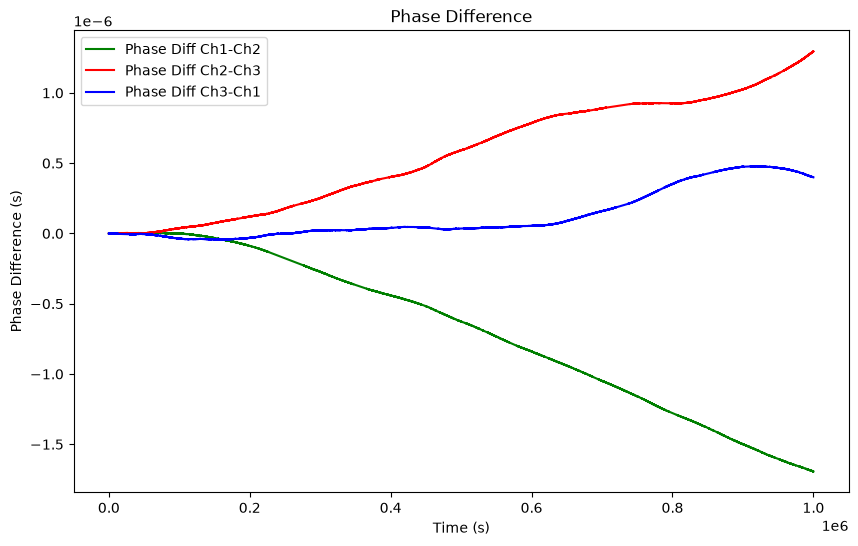

In [5]:

#   Plot each channel phase difference vs. time

plt.figure(figsize=(10, 6))
plt.plot(phase_diff_1_2, 'g', label='Phase Diff Ch1-Ch2')
plt.plot(phase_diff_2_3, color = 'r', label='Phase Diff Ch2-Ch3')
plt.plot(phase_diff_3_1, color = 'b', label='Phase Diff Ch3-Ch1')
plt.xlabel('Time (s)')
plt.ylabel('Phase Difference (s)')
plt.title('Phase Difference')
plt.legend()
plt.show()

## Plot TCH OADEV with Error Bars using error_bars_list and plot_tch_error_bars

Note: For illustration purposes, minimum degrees of freedom is set to 1.

Noise type for Clock 1 at tau = 1.0 changed to White PM.
Noise type for Clock 1 at tau = 10.0 changed to Flicker PM.
Noise type for Clock 1 at tau = 40.0 changed to White FM.
Noise type for Clock 1 at tau = 100.0 changed to Flicker PM.
Noise type for Clock 1 at tau = 400.0 changed to White FM.
Noise type for Clock 1 at tau = 1000.0 changed to Flicker FM.
Noise type for Clock 1 at tau = 2000.0 changed to Random Walk FM.


C:\Users\becks\OneDrive\Desktop\Git_Repos\deviation_confidence_intervals_1\src\clock_confidence_intervals\confidence_intervals.py:741: UserWarning: Only 8.6 remaining degrees of freedom (<10) at tau=10000.0 for clock 1 
The confidence interval calculation parameters are degraded, 
and the TCH may return a negative variance. Use these bars with caution.
C:\Users\becks\OneDrive\Desktop\Git_Repos\deviation_confidence_intervals_1\src\clock_confidence_intervals\confidence_intervals.py:741: UserWarning: Only 5.2 remaining degrees of freedom (<10) at tau=20000.0 for clock 1 
The confidence interval calculation parameters are degraded, 
and the TCH may return a negative variance. Use these bars with caution.
C:\Users\becks\OneDrive\Desktop\Git_Repos\deviation_confidence_intervals_1\src\clock_confidence_intervals\confidence_intervals.py:741: UserWarning: Remaining degrees of freedom of 3.2 is below the minimum df 5 at tau=40000.0 for clock 1. Returning NaN error bars.
C:\Users\becks\AppData\Loc

Noise type for Clock 2 at tau = 1.0 changed to White PM.
Noise type for Clock 2 at tau = 10.0 changed to Flicker PM.
Noise type for Clock 2 at tau = 40.0 changed to White FM.
Noise type for Clock 2 at tau = 100.0 changed to Flicker PM.
Noise type for Clock 2 at tau = 400.0 changed to White FM.
Noise type for Clock 2 at tau = 1000.0 changed to Flicker FM.
Noise type for Clock 2 at tau = 2000.0 changed to Random Walk FM.


C:\Users\becks\OneDrive\Desktop\Git_Repos\deviation_confidence_intervals_1\src\clock_confidence_intervals\confidence_intervals.py:741: UserWarning: Only 6.6 remaining degrees of freedom (<10) at tau=20000.0 for clock 2 
The confidence interval calculation parameters are degraded, 
and the TCH may return a negative variance. Use these bars with caution.
C:\Users\becks\OneDrive\Desktop\Git_Repos\deviation_confidence_intervals_1\src\clock_confidence_intervals\confidence_intervals.py:741: UserWarning: Remaining degrees of freedom of 3.1 is below the minimum df 5 at tau=40000.0 for clock 2. Returning NaN error bars.
C:\Users\becks\AppData\Local\Temp\ipykernel_24292\201651245.py:19: UserWarning: Skipping tau=40000.0 for clock 2 because error bars could not be computed.
C:\Users\becks\OneDrive\Desktop\Git_Repos\deviation_confidence_intervals_1\src\clock_confidence_intervals\confidence_intervals.py:741: UserWarning: Clock differences for 2 vs other clocks have different noise types 
at tau=100

Noise type for Clock 3 at tau = 1.0 changed to White PM.
Noise type for Clock 3 at tau = 10.0 changed to Flicker PM.
Noise type for Clock 3 at tau = 20.0 changed to White FM.
Noise type for Clock 3 at tau = 100.0 changed to Flicker PM.
Noise type for Clock 3 at tau = 400.0 changed to White FM.
Noise type for Clock 3 at tau = 1000.0 changed to Flicker FM.
Noise type for Clock 3 at tau = 2000.0 changed to Random Walk FM.


C:\Users\becks\OneDrive\Desktop\Git_Repos\deviation_confidence_intervals_1\src\clock_confidence_intervals\confidence_intervals.py:741: UserWarning: Clock differences for 3 vs other clocks have different noise types 
at tau=100000.0, with alpha_1=-0.33981491762134164 and alpha_2=-2.415001587445011. Taking noise type corresponding to least degrees of freedom.
C:\Users\becks\OneDrive\Desktop\Git_Repos\deviation_confidence_intervals_1\src\clock_confidence_intervals\confidence_intervals.py:741: UserWarning: Only 6.0 remaining degrees of freedom (<10) at tau=100000.0 for clock 3 
The confidence interval calculation parameters are degraded, 
and the TCH may return a negative variance. Use these bars with caution.
C:\Users\becks\OneDrive\Desktop\Git_Repos\deviation_confidence_intervals_1\src\clock_confidence_intervals\confidence_intervals.py:741: UserWarning: Clock differences for 3 vs other clocks have different noise types 
at tau=200000.0, with alpha_1=5.086000813664318 and alpha_2=3.489234

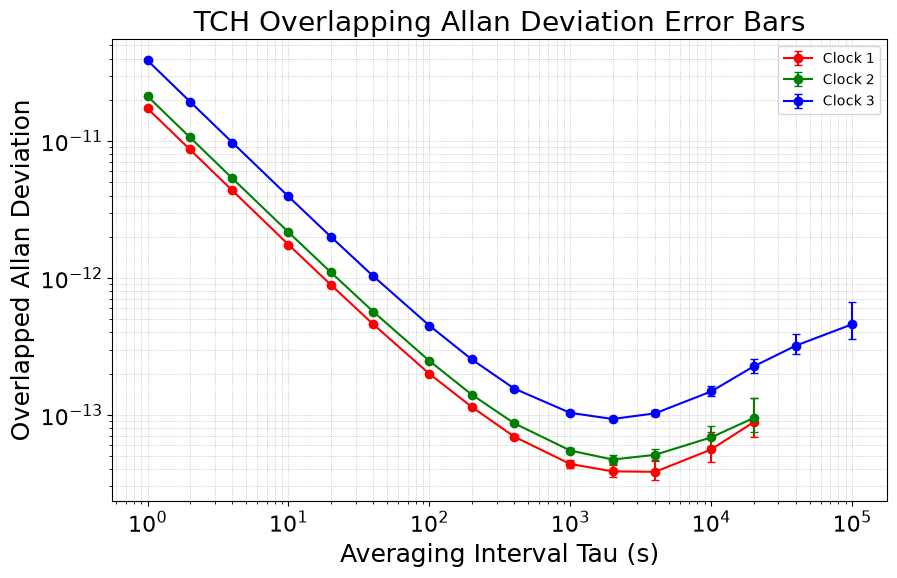

In [6]:
'''Tau Value to Calculate TCH ADEVs for:
Array of tau values for which to compute measurement. Alternatively one of the keywords: “all”, “octave”, “decade”
(corresponding to AllanTools ADEV, OADEV, etc. keywords).

keyword: averaging-factors

“all”: 1, 2, 3, 4, …, len(data)

“octave”: 1, 2, 4, 8, 16, 32, …

“decade”: 1, 2, 4, 10, 20, 40, 100, …

“log10”: approx. 10 points per decade

'''
test_taus = 'decade'

#   Defaults to OADEV if no dev_function is entered
error_bars_1, error_bars_2, error_bars_3 = error_bars_tch_list([phase_diff_1_2, phase_diff_2_3, phase_diff_3_1], rate = rate,
                                                           taus = test_taus, confidence = 0.68, dev_function = allantools.oadev,
                                                             bias_correct = True, min_df = 5)

fig, ax = plt.subplots(figsize = (10,6))




#   Clock Names (Clock 1 corresponds to Ch 1, etc.):
clock_1 = 'Clock 1'
clock_2 = 'Clock 2'
clock_3 = 'Clock 3'
plot_error_bars(error_bars_1, error_bars_2, error_bars_3, ax = ax,
                     labels = [clock_1, clock_2, clock_3], title = 'TCH Overlapping Allan Deviation Error Bars', title_font_size = 20,
                     axis_labels= ('Averaging Interval Tau (s)', 'Overlapped Allan Deviation'),
                     axis_label_font_size = 18, axis_tick_font_size = 16)


plt.show()


### Optional: Print List of Calculated OADEV and Error Bars

In [7]:
#   Print Tau, ADEV, and Error Bars for Each Clock (after running error_bars_list() function)

def print_error_bar_table(clock_data, clock_name):
    header = f"{'Tau (s)':>14}{'ADEV':>16}{'Lower':>16}{'Upper':>16}"
    print(clock_name)
    print(header)
    print('-' * len(header))
    for tau, dev, (lower, upper), df in clock_data:
        print(f"{tau:>14.4g}{dev:>16.6e}{lower:>16.6e}{upper:>16.6e}")
    print()

print_error_bar_table(error_bars_1, clock_1)
print_error_bar_table(error_bars_2, clock_2)
print_error_bar_table(error_bars_3, clock_3)

Clock 1
       Tau (s)            ADEV           Lower           Upper
--------------------------------------------------------------
             1    1.730806e-11    1.726006e-11    1.735639e-11
             2    8.679050e-12    8.654990e-12    8.703272e-12
             4    4.354221e-12    4.342153e-12    4.366371e-12
            10    1.753858e-12    1.746877e-12    1.760907e-12
            20    8.915581e-13    8.872786e-13    8.958877e-13
            40    4.588173e-13    4.541171e-13    4.636365e-13
           100    1.998082e-13    1.982184e-13    2.014289e-13
           200    1.143838e-13    1.132523e-13    1.155429e-13
           400    6.941268e-14    6.721017e-14    7.179743e-14
          1000    4.379711e-14    4.128689e-14    4.670935e-14
          2000    3.870828e-14    3.531093e-14    4.301661e-14
          4000    3.838808e-14    3.325258e-14    4.596783e-14
         1e+04    5.591418e-14    4.549724e-14    7.483409e-14
         2e+04    8.842512e-14    6.849213e-14 

### Plot 2-Port OADEV with Error Bars

Note: For illustration purposes, minimum degree of freedom is set to 5.

Noise type changed to White PM at tau = 1.0 for 2-port deviation.
Noise type changed to Flicker PM at tau = 10.0 for 2-port deviation.
Noise type changed to White FM at tau = 27.0 for 2-port deviation.
Noise type changed to White PM at tau = 54.0 for 2-port deviation.
Noise type changed to Flicker PM at tau = 68.0 for 2-port deviation.
Noise type changed to White FM at tau = 276.0 for 2-port deviation.
Noise type changed to Flicker FM at tau = 704.0 for 2-port deviation.
Noise type changed to Random Walk FM at tau = 1421.0 for 2-port deviation.
Noise type changed to White FM at tau = 60209.0 for 2-port deviation.


C:\Users\becks\OneDrive\Desktop\Git_Repos\deviation_confidence_intervals_1\src\clock_confidence_intervals\confidence_intervals.py:564: UserWarning: Identified alpha not in accepted range (2, 1, 0, -1, -2); defaulting to RWFM for conservative df estimate.
C:\Users\becks\OneDrive\Desktop\Git_Repos\deviation_confidence_intervals_1\src\clock_confidence_intervals\confidence_intervals.py:564: UserWarning: Remaining degrees of freedom of 4.5 is below the minimum df 5 at tau=153617.0. Returning NaN error bars.
C:\Users\becks\AppData\Local\Temp\ipykernel_24292\3790154005.py:27: UserWarning: Skipping tau=153617.0 because error bars could not be computed.
C:\Users\becks\OneDrive\Desktop\Git_Repos\deviation_confidence_intervals_1\src\clock_confidence_intervals\confidence_intervals.py:564: UserWarning: Remaining degrees of freedom of 3.3 is below the minimum df 5 at tau=194149.0. Returning NaN error bars.
C:\Users\becks\AppData\Local\Temp\ipykernel_24292\3790154005.py:27: UserWarning: Skipping tau=

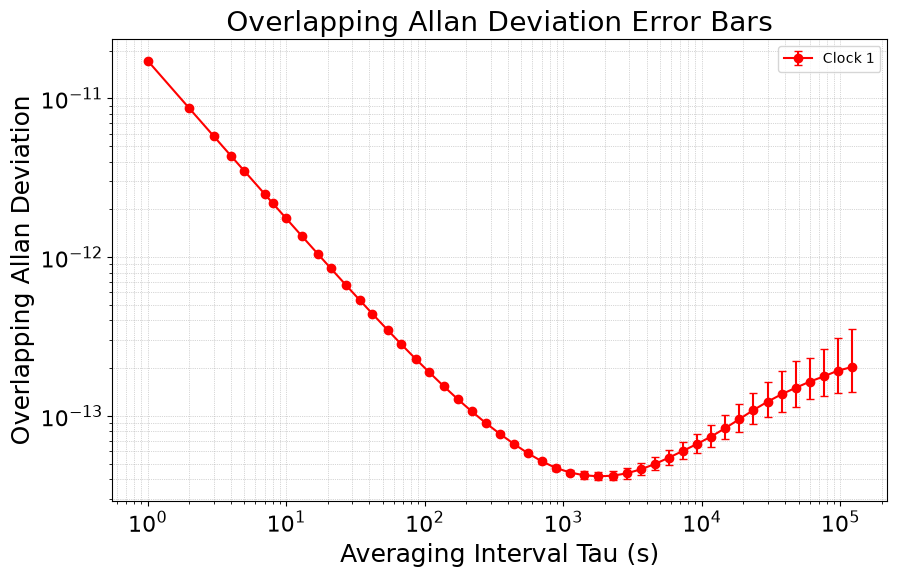

In [8]:
'''Tau Value to Calculate ADEVs for:
Array of tau values for which to compute measurement. Alternatively one of the keywords: “all”, “octave”, “decade”
(corresponding to AllanTools ADEV, OADEV, etc. keywords).

keyword: averaging-factors

“all”: 1, 2, 3, 4, …, len(data)

“octave”: 1, 2, 4, 8, 16, 32, …

“decade”: 1, 2, 4, 10, 20, 40, 100, …

“log10”: approx. 10 points per decade

Warning: 'all' takes a VERY long time to compute (on the order of days... or longer
 for a 21 hour data set at 100Hz (~7 x 10^6 values).

 ('decade' ran for 5 minutes, 'octave' for 6.5m, 'log10' for 22m)
'''
phase_diff = clock_one_phase

test_taus = 'log10'
m_vals = np.arange(1, 1e3,1)
tau_vals = m_vals/rate

#   Defaults to OADEV if no dev_function is entered
error_bars = error_bars_list(phase_diff, rate = rate, dev_data = None, 
                                                           taus = test_taus, confidence = 0.95,
                                                           dev_function = allantools.oadev, min_df = 5)

fig, ax = plt.subplots(figsize = (10,6))




plot_error_bars(error_bars, ax = ax,
                     labels = ['Clock 1'], title = 'Overlapping Allan Deviation Error Bars', title_font_size = 20,
                     axis_labels= ('Averaging Interval Tau (s)', 'Overlapping Allan Deviation'),
                     axis_label_font_size = 18, axis_tick_font_size = 16)


plt.show()
